# Repeated terahertz waveforms: noise, amplitude drift and timing jitter


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `terahertz_waveform_noise_calibration` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：waveforms (1, 50, 267) float64：Photocurrent in pA; batch, repeated scan, native time sample.。恢复目标：common latent waveform pA、amplitude/delay drift与三noise amplitudes。

获取模型：每scan为Fourier-shifted/scaled latent waveform；variance由additive、signal幅度与导数三项构成。实际恢复算法：solvers.reconstruct显式联合Gaussian NLL/gradient的BFGS，固定首scan amplitude/time gauge。语义类型为 `inverse_calibration`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:165无latent/noise真值；baseline为六项原始likelihood估计。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：terahertz_waveform_noise_calibration.ipynb单元0：5. Results；terahertz_waveform_noise_calibration.ipynb单元5有保存图；图内容由该单元调用的本地visualization函数生成；terahertz_waveform_noise_calibration.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；terahertz_waveform_noise_calibration.ipynb单元8：Fresh sample-count and noise-model sensitivity；terahertz_waveform_noise_calibration.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元1, 3, 5, 7, 9（从0计数）。代码单元6个，带execution_count的6个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：已存cell3报告actual_success=false，同时给出小归一化gradient、正Hessian与Newton诊断；不能把参考parity写成优化器成功或物理准确。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


We actively reconstruct **all 50 measured air-reference traces and all 267 native samples**, jointly estimating the common latent waveform, every relative amplitude and delay, and all three noise amplitudes. The public input contains only measured photocurrent. Actual latent truth is unavailable; the independently executed original method is a separately labeled reference.

The noise/drift likelihood is from Mohtashemi et al., *Optics Express* (2021), DOI 10.1364/OE.417724, with the modern joint-waveform THzTools implementation described by Posada Loaiza et al., *JOSS* (2024), DOI 10.21105/joss.07542. Data are the authors' MIT-licensed 2017 air scans, archived with the 2021 software. The historical MATLAB script selected 256 samples and approximated parts of the variance using a common waveform. This benchmark preserves the complete native 267-sample data and selected modern per-secondary-waveform likelihood; it does not relabel a historical paper table as a reproduced measurement.

## 2. Data

`data/raw_data.npz` contains the full author-deposited measured traces. Voltage was converted to calibrated photocurrent with the acquisition gain. No samples were cropped, denoised or synthetically generated.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| `waveforms` | `(1, 50, 267)` | `float64` | Photocurrent in pA; batch, repeated scan, native time sample. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Measurement condition | Air-reference repeated THz time traces | — | Instrument-noise/drift experiment, without a material specimen inversion. |
| Acquisition date | 2017-03-20 | — | Author data record. |
| Repeated acquisitions | 50 | 1 | $M$; original filename order. |
| Native samples per trace | 267 | 1 | $N$; entire recorded window. |
| Sampling interval | 0.05003462406015038 | ps | $\Delta t$; mean native time-coordinate spacing. |
| Relative time origin | 0 | ps | First supplied sample; absolute time offset is absorbed by the waveform gauge. |
| Transimpedance gain | 5e7 | V/A | Original voltage divided by this gain yields current in amperes. |
| Public amplitude conversion | Original voltage × 1e12 / 5e7 | pA | Exact author-specified conversion. |
| Shift convention | $\mu(t-\eta)$ | — | Positive delay shifts a feature toward larger sample time. |
| Fourier boundary | Periodic, real transform on all 267 samples | — | Odd sample count has no separate Nyquist coefficient. |
| Drift gauge | First amplitude 1; first delay 0 | — | Fixes amplitude and delay nonidentifiability. |
| Sample-noise assumptions | Gaussian; independent conditional on drift and waveform | — | Variance depends on each scan's expected waveform and its derivative. |
| Noise parameters | Unknown and shared across all scans | — | Additive, multiplicative and timing-jitter amplitudes must all be inferred. |

## 3. Physics

### Physical and statistical model

For scan $j$, the expected waveform is $\zeta_j=a_j S(\eta_j)\mu$, where $\mu$ is the latent photocurrent waveform, $a_j$ is relative amplitude and $S(\eta_j)$ shifts $\mu(t)$ to $\mu(t-\eta_j)$. The first scan fixes $a_0=1$, $\eta_0=0$; this is a gauge convention, not known noiseless truth. A Fourier coefficient at angular frequency $\omega$ is multiplied by $e^{-i\omega\eta}$ for shifting and $i\omega$ for differentiation. The periodic Fourier operator acts on the entire odd-length native window.

Conditional on the waveform and drift, samples are independent Gaussian variables with variance $v=\alpha^2+\beta^2\zeta^2+\tau^2(D\zeta)^2$. The three noise amplitudes have units pA, dimensionless and ps. $D$ is the physical time derivative. The minimized negative log likelihood is $L=\frac12\sum[\log v+(x-\zeta)^2/v]$, omitting its fixed Gaussian constant. Its analytic gradient must include changes in both the mean and variance.

The local implementation explicitly evaluates the Fourier operators, positive log variances, parameter scales, cost, all gradient blocks, initial variance regression and finite-sample correction. BFGS is the general numerical optimizer. The three output noise amplitudes include the source factor $\sqrt{M/(M-1)}$; NLL and stationarity diagnostics describe the uncorrected MLE variables. All 368 free parameters remain in the selected inverse.

## 4. Method

### Honest optimizer stopping and independent quality checks

The canonical original and fresh BFGS runs stop with **success=False, precision loss**, and do not satisfy the requested scaled-gradient tolerance 1e-6. We preserve this result and message. Independent original-function directional finite differences, positive-definite curvature and a negligible possible likelihood improvement support a near-stationary local minimum. No looser tolerance or replacement reconstruction makes the flag true.

Below, curvature and a diagnostic Newton displacement are computed from the fresh analytic gradient solely to quantify the stopping quality. The submitted arrays and original reference remain the selected canonical BFGS result. Curvature marginal errors are joint observed-information approximations conditional on this noise model/data, not independently verified physical uncertainty or coverage guarantees. Source covariance uses a signed-coordinate convention for waveform deviations; marginal variances are unaffected, and off-diagonal values are not presented as physical covariance.

Optimize all 368 scaled variables: 267 latent waveform samples, 49 amplitude deviations, 49 delays and three positive log-variance parameters. Fix the first scan's amplitude/delay gauge. With measured photocurrent $x$, predicted secondary waveform $\zeta=aS(\eta)\mu$ and conditional variance $v$, BFGS minimizes

$$
L=\tfrac12\sum_{j,k}[\log v_{jk}+(x_{jk}-\zeta_{jk})^2/v_{jk}].
$$

Analytic derivatives include both mean and variance dependence. The published finite-M factor $\sqrt{M/(M-1)}$ corrects reported noise amplitudes, while likelihood/stationarity diagnostics refer to the uncorrected MLE. The canonical precision-loss stop is preserved; diagnostic Newton displacement does not replace the submitted result.

## 5. Results

The full 50-scan fit, 10/25-scan refits and additive-only ablation are actual local computations. Noise units are pA, dimensionless amplitude fraction and ps; variance is pA^2. Joint-curvature error bars are model-conditional local approximations, not empirical uncertainty coverage.


## Current benchmark contract v2

The v2 evaluator uses the independently evaluated mean heteroscedastic Gaussian negative log likelihood, with predeclared excess tolerance 1e-6 over an attainable fit. Reported noise amplitudes retain the sqrt(50/49) finite-sample correction; likelihood variances undo it. Expected waveforms and corrected noise standard deviations must satisfy the public periodic Fourier model to relative L2 1e-7. Period-equivalent delays are accepted. This certifies a conditional statistical fit, not an independently calibrated noiseless waveform. Independent synthetic drift/variance and periodic-alias controls pass; inflated consistent noise is rejected. The cleaned reconstruction algorithm is unchanged. Historical displayed method-identity numbers describe v1 and are not current pass boundaries.


In [1]:
from pathlib import Path
import sys,json,time,hashlib,subprocess,platform
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').exists()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,DT_PS
from src.solvers import reconstruct
from src.physics_model import gradient,objective
from src.visualization import experiments,make_figures,relative_error
x=load_data(ROOT/'data/raw_data.npz')
print('Measured traces:',x.shape,'dtype:',x.dtype,'sampling interval (ps):',DT_PS)


Measured traces: (50, 267) dtype: float64 sampling interval (ps): 0.05003462406015038


In [2]:
start=time.perf_counter()
fresh,diagnostic=reconstruct(x)
reconstruction_runtime_s=time.perf_counter()-start
output=ROOT/'output/reconstruction.npz';output.parent.mkdir(exist_ok=True)
np.savez_compressed(output,**fresh)
reference=dict(np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False))
errors={k:relative_error(fresh[k],reference[k]) for k in fresh}
cmd=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(output),'--report',str(ROOT/'output/judge_report.json')]
p=subprocess.run(cmd,capture_output=True,text=True)
assert p.returncode==0,(p.stdout,p.stderr)
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
assert report['status']=='pass'
print('Fresh reconstruction runtime (s):',reconstruction_runtime_s)
print('Original-reference relative errors:',json.dumps(errors,indent=2))
print('Independent Judge metrics:',json.dumps(report['metrics'],indent=2))
print('Actual selected optimizer diagnostics:',{k:diagnostic[k] for k in ['success','message','iterations','nll','gradient_inf','gradient_inf_per_observation']})


Fresh reconstruction runtime (s): 1.2754376998636872
Original-reference relative errors: {
  "reconstruction": 0.0,
  "amplitude": 0.0,
  "delay": 0.0,
  "noise": 0.0,
  "expected_waveforms": 0.0,
  "noise_std": 0.0
}
Independent Judge metrics: {
  "reconstruction": 0.0,
  "amplitude": 0.0,
  "delay": 0.0,
  "noise_component_0": 0.0,
  "noise_component_1": 0.0,
  "noise_component_2": 0.0,
  "expected_waveforms": 0.0,
  "noise_std": 0.0
}
Actual selected optimizer diagnostics: {'success': False, 'message': 'Desired error not necessarily achieved due to precision loss.', 'iterations': 169, 'nll': 5066.818699894164, 'gradient_inf': 1.996988099860724e-05, 'gradient_inf_per_observation': 1.4958712358507296e-09}


In [3]:
variants,uncertainties,additive,source,measurements=experiments(x,fresh,diagnostic)
H=uncertainties[50]['hessian'];Hs=(H+H.T)/2
g=gradient(diagnostic['theta'],x,diagnostic['scales'])
step=np.linalg.solve(Hs,g)
trial=diagnostic['theta']-step
stationarity={'actual_success':diagnostic['success'],'scaled_gradient_max':float(abs(g).max()),'gradient_max_per_observation':float(abs(g).max()/x.size),'hessian_min_eigenvalue':float(np.linalg.eigvalsh(Hs).min()),'newton_decrement_diagnostic_only':float(g@step),'possible_nll_gain_diagnostic_only':float(objective(diagnostic['theta'],x,diagnostic['scales'])-objective(trial,x,diagnostic['scales'])),'trial_gradient_max_diagnostic_only':float(abs(gradient(trial,x,diagnostic['scales'])).max())}
print('Fresh stationarity audit:',json.dumps(stationarity,indent=2))
measurements.update(reconstruction_runtime_s=reconstruction_runtime_s,selected_diagnostic={k:diagnostic[k] for k in ['success','message','iterations','nll','gradient_inf','gradient_inf_per_observation']},stationarity_audit=stationarity,upstream_relative_errors=errors,raw_data_sha256=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest(),environment={'python':sys.version,'numpy':np.__version__,'platform':platform.platform()})
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2),encoding='utf8')
print(json.dumps(measurements,indent=2))
figures=make_figures(x,fresh,diagnostic,reference,variants,uncertainties,additive,source)
plt.close('all')


Fresh stationarity audit: {
  "actual_success": false,
  "scaled_gradient_max": 1.996988099860724e-05,
  "gradient_max_per_observation": 1.4958712358507296e-09,
  "hessian_min_eigenvalue": 0.0701217874034354,
  "newton_decrement_diagnostic_only": 5.414536952946593e-11,
  "possible_nll_gain_diagnostic_only": 2.4556356947869062e-11,
  "trial_gradient_max_diagnostic_only": 5.527477382586661e-12
}
{
  "method": "Fresh selected full joint BFGS; independent Hessian diagnostics do not replace it",
  "sample_counts": {
    "50": {
      "noise": [
        0.6276475127579297,
        0.01567228705405409,
        0.0017742194019303627
      ],
      "err_noise": [
        0.005422872747771413,
        0.00032103509261619586,
        6.620475445837538e-05
      ],
      "success": false,
      "message": "Desired error not necessarily achieved due to precision loss.",
      "nll": 5066.818699894164,
      "gradient_inf_per_observation": 1.4958712358507296e-09
    },
    "10": {
      "noise": [
 

### Measured waveform, latent signal and drift

All 50 raw traces retain the full recorded time/amplitude range. The latent curve is compared separately with the original result and uncorrected sample mean; the inset displays their actual difference in pA. Latent amplitude/delay belongs to the first-trace gauge. Relative amplitude and timing drift are plotted for every acquisition with fresh joint-curvature marginal errors; gauge-entry errors are exactly zero by definition. These values describe instrument/acquisition drift, not material heterogeneity.


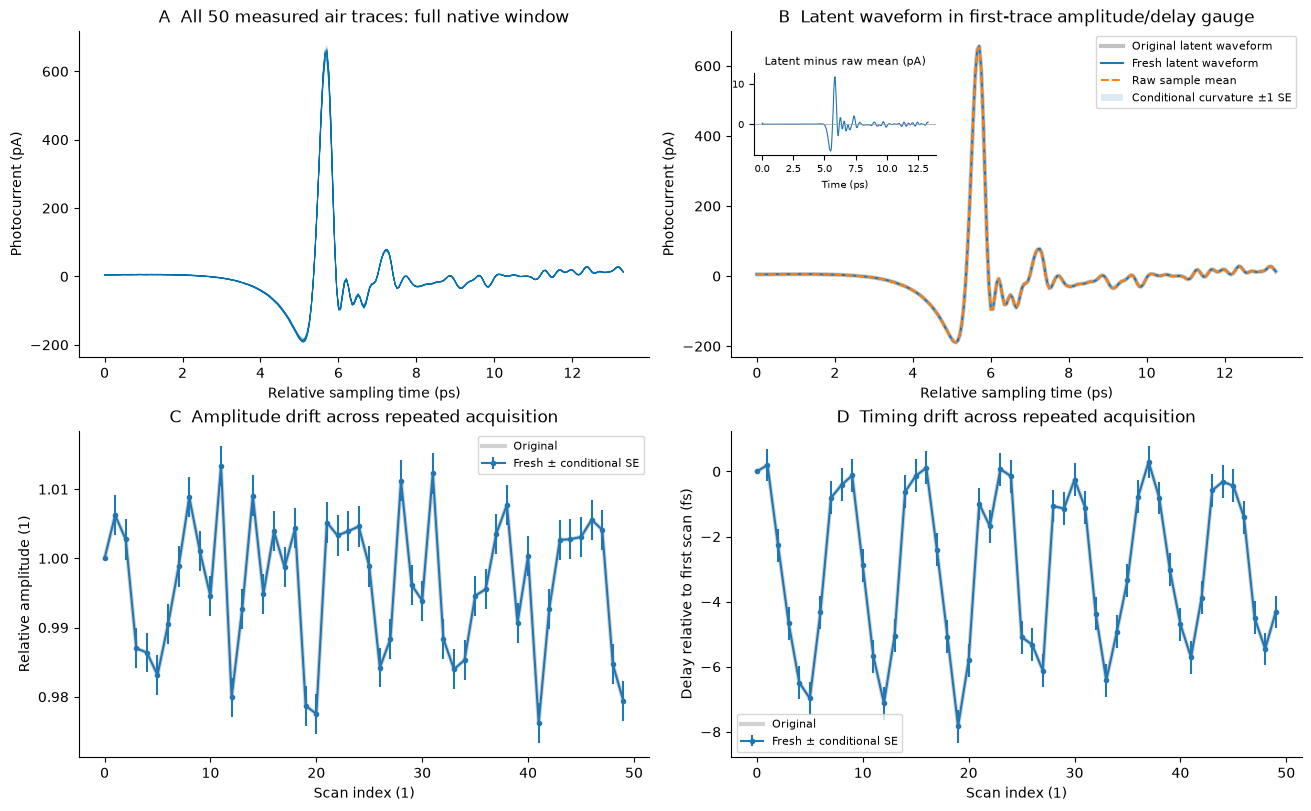

In [4]:
display(figures['reconstruction'])
plt.close(figures['reconstruction'])


### Variance and residual diagnostics

The three modeled variance contributions are averaged across the actual fitted secondary waveforms. The total is compared with raw observed sample variance and the variance of drift-removed residuals, in pA^2. Every standardized residual trace is shown; its denominator uses the reported finite-M-corrected noise. The QQ plot compares fitted residual quantiles with a standard normal without claiming an iid goodness-of-fit p-value after nuisance fitting. Tail deviations remain visible. The likelihood trace records actual accepted BFGS iterates and labels the precision-loss stop.


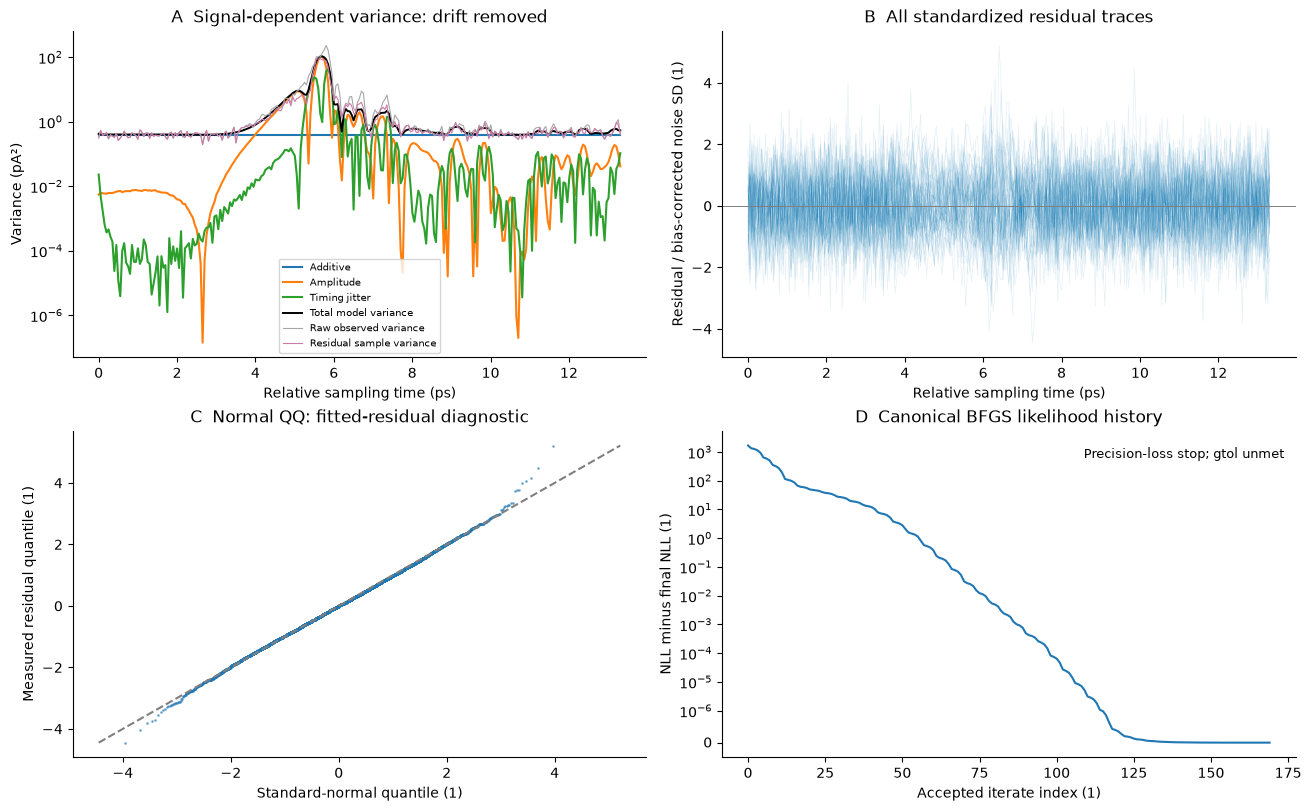

In [5]:
display(figures['residuals'])
plt.close(figures['residuals'])


### Fresh sample-count and noise-model sensitivity

The first 10 and first 25 real acquired scans are fully refitted, retaining all 267 time samples and the complete joint unknowns. Each noise estimate and its fresh model-based marginal error is shown against the full 50-scan result. Acquisition prefixes are correlated datasets, not independent Monte Carlo replicates; error bars do not establish empirical coverage.

The additive-only comparison fixes the other log variances at -100 and refits the remaining waveform/drifts/additive noise. It is an explicitly labeled model ablation. Its standardized residuals understate noise around the pulse and overstate background noise, whereas the complete three-source model accounts for waveform-dependent variability. No optional comparison substitutes for the selected full reconstruction.


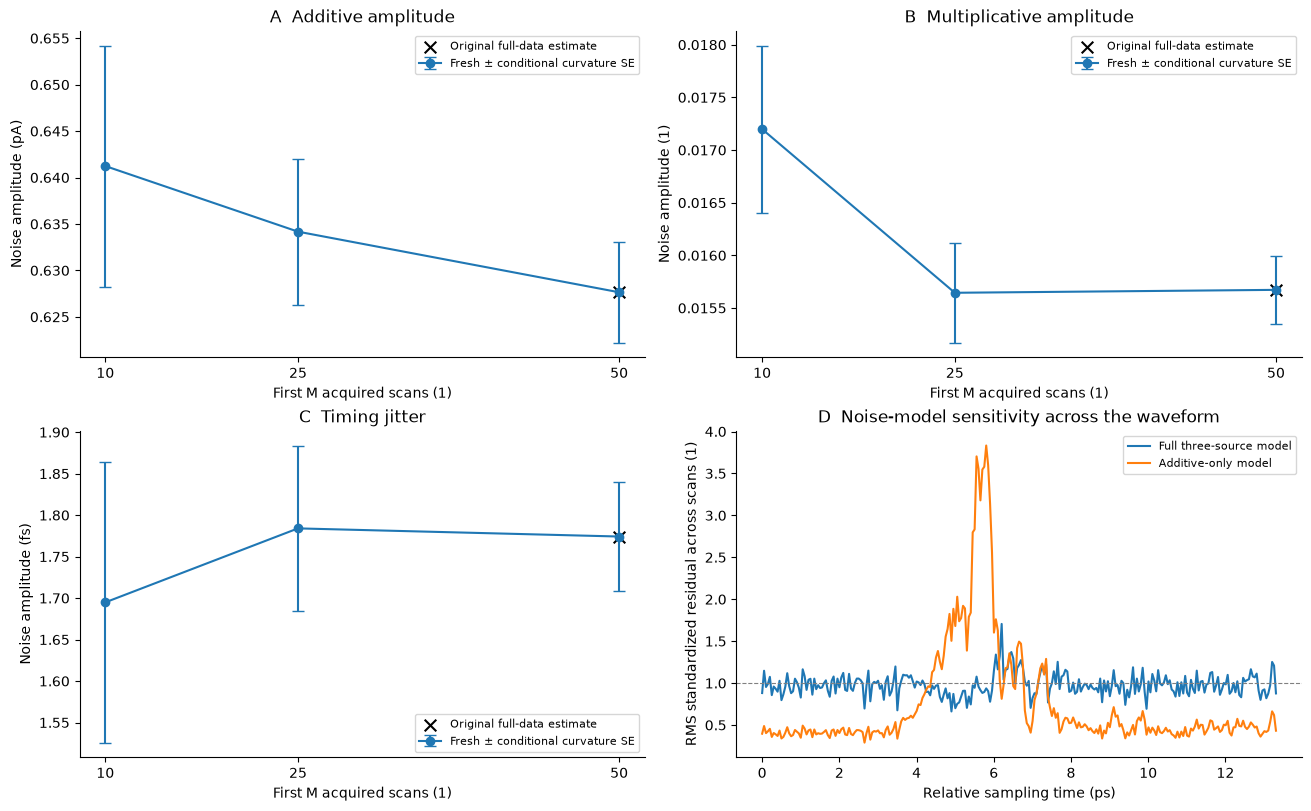

In [6]:
display(figures['sensitivity'])
plt.close(figures['sensitivity'])


## 6. Conclusion

### Interpretation and limitations

The complete-data corrected estimates are approximately 0.62765 pA additive noise, 0.015672 multiplicative amplitude, and 1.7742 fs timing jitter. The local full pipeline reproduces the independently executed original arrays exactly on this environment. That agreement is method parity, not latent-signal truth.

The likelihood assumes independent Gaussian samples conditional on drift and waveform, and a periodic band-limited shift/derivative over a finite native window. It does not model every colored-noise or nonstationary process. The finite-M correction is approximate and does not remove all incidental-parameter bias. Hessian marginal errors assume the chosen statistical model and local curvature; they are not calibrated coverage statements. The full-data optimizer's false precision-loss flag and unmet gtol remain reported alongside the positive curvature and negligible diagnostic Newton improvement. Diagnostic Newton arrays never become the reconstruction or hidden reference.
